Starting Wireless Sensor Network simulation...

========== WSN SIMULATION RESULTS ==========
Number of nodes: 60
Initial energy per node: 0.5 J
Simulation rounds: 400
--------------------------------------------------------------------
Method                      First death     50% death   Alive at end
LEACH-style baseline                400           400             60
Cuckoo Search                       400           400             60
--------------------------------------------------------------------


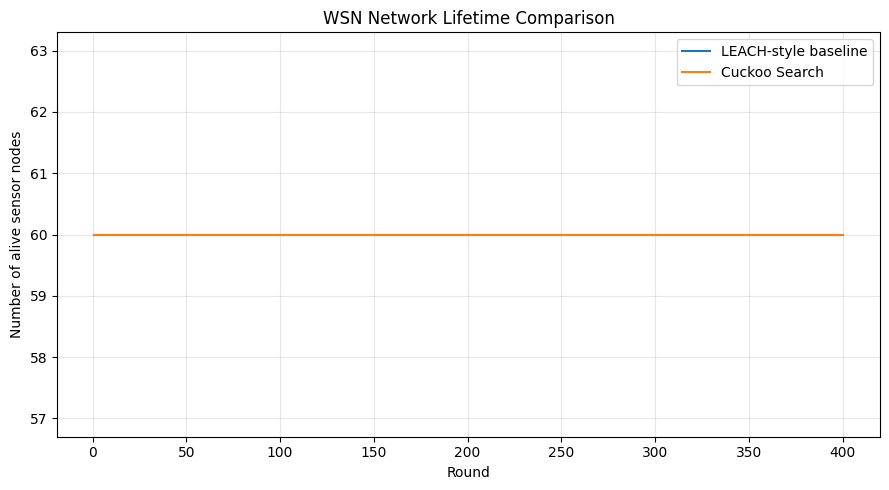

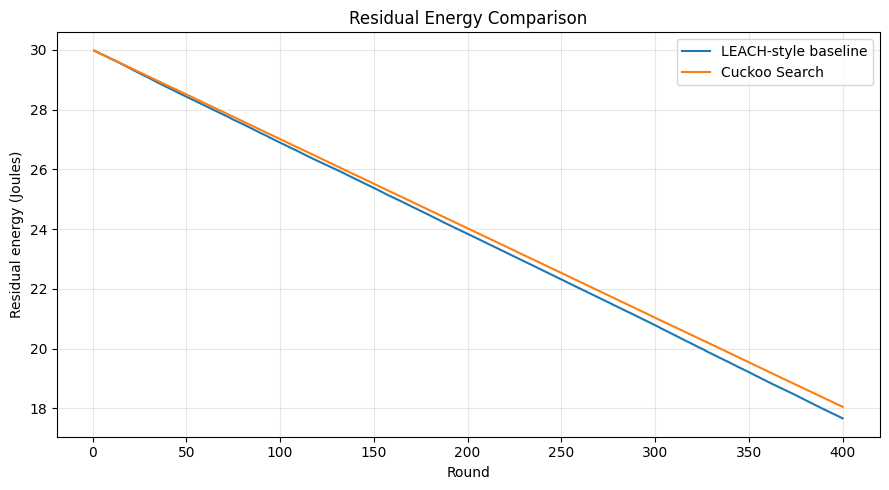

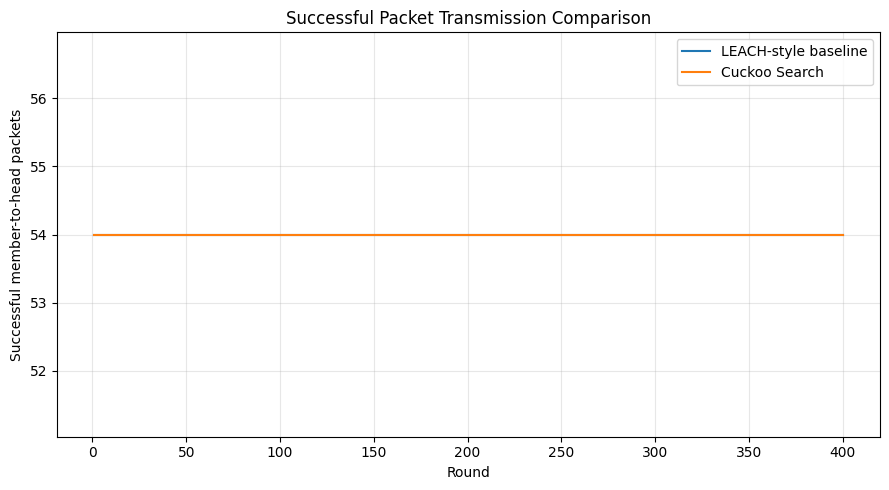

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# IMPROVED CUCKOO SEARCH FOR WIRELESS SENSOR NETWORKS
# Energy-efficient clustering and routing simulation
# ============================================================

# 1. NETWORK PARAMETERS
SEED = 7
NUM_NODES = 60
AREA_WIDTH = 100
AREA_HEIGHT = 100
BASE_STATION = np.array([50.0, 150.0])
INITIAL_ENERGY = 0.5
ROUNDS = 400
CLUSTER_HEAD_FRACTION = 0.10

# 2. RADIO ENERGY MODEL
E_ELEC = 50e-9
E_DA = 5e-9
E_FS = 10e-12
E_MP = 0.0013e-12
PACKET_BITS = 4000
CONTROL_BITS = 200

# 3. CUCKOO SEARCH PARAMETERS
NUM_NESTS = 20
MAX_ITERATIONS = 35
PA = 0.25
STEP_SCALE = 0.12


# ============================================================
# ENERGY CALCULATIONS
# ============================================================

def transmit_energy(bits, distance):
    """Calculate energy required to transmit data."""
    d0 = np.sqrt(E_FS / E_MP)

    if distance < d0:
        amplifier = E_FS * distance ** 2
    else:
        amplifier = E_MP * distance ** 4

    return bits * (E_ELEC + amplifier)


def receive_energy(bits):
    """Calculate energy required to receive data."""
    return bits * E_ELEC


# ============================================================
# CREATE WIRELESS SENSOR NETWORK
# ============================================================

def create_network(seed=SEED):
    rng = np.random.default_rng(seed)

    positions = rng.uniform(
        low=[0, 0],
        high=[AREA_WIDTH, AREA_HEIGHT],
        size=(NUM_NODES, 2)
    )

    energy = np.full(NUM_NODES, INITIAL_ENERGY)

    return rng, positions, energy


def number_of_heads(number_alive):
    """Choose the target number of cluster heads."""
    return max(
        1,
        min(
            number_alive,
            round(NUM_NODES * CLUSTER_HEAD_FRACTION)
        )
    )


# ============================================================
# FITNESS FUNCTION
# ============================================================

def fitness(mask, positions, energy):
    """
    Lower fitness is better.

    Considers:
    1. Distance between sensor nodes and cluster heads
    2. Residual energy of cluster heads
    3. Number of cluster heads
    4. Cluster load balancing
    """

    alive = np.where(energy > 0)[0]
    heads = np.where(mask & (energy > 0))[0]

    if len(alive) == 0 or len(heads) == 0:
        return 1e9

    distances = np.linalg.norm(
        positions[alive, None, :] - positions[heads][None, :, :],
        axis=2
    )

    nearest_distances = np.min(distances, axis=1)

    distance_cost = (
        np.mean(nearest_distances)
        / np.hypot(AREA_WIDTH, AREA_HEIGHT)
    )

    energy_cost = np.mean(
        1 - np.clip(energy[heads] / INITIAL_ENERGY, 0, 1)
    )

    target = number_of_heads(len(alive))

    count_cost = abs(len(heads) - target) / target

    assignments = np.argmin(distances, axis=1)

    loads = np.bincount(
        assignments,
        minlength=len(heads)
    )

    load_cost = np.std(loads) / max(np.mean(loads), 1)

    total_fitness = (
        0.60 * distance_cost
        + 0.20 * energy_cost
        + 0.10 * count_cost
        + 0.10 * load_cost
    )

    return total_fitness


# ============================================================
# CUCKOO SEARCH ALGORITHM
# ============================================================

def cuckoo_search(positions, energy, rng):
    """
    Each nest represents a possible selection of cluster heads.
    Heavy-tailed random steps explore alternative solutions.
    """

    alive = energy > 0
    alive_nodes = np.where(alive)[0]

    if len(alive_nodes) == 0:
        return np.array([], dtype=int)

    k = number_of_heads(len(alive_nodes))
    n = len(energy)

    # Ensure each candidate has exactly k living cluster heads.
    def repair(candidate):
        candidate = candidate.copy()
        candidate &= alive

        selected = np.where(candidate)[0]

        if len(selected) > k:
            keep = rng.choice(selected, size=k, replace=False)
            candidate[:] = False
            candidate[keep] = True

        elif len(selected) < k:
            available = np.where(alive & ~candidate)[0]
            missing = k - len(selected)

            if len(available) > 0:
                add = rng.choice(
                    available,
                    size=min(missing, len(available)),
                    replace=False
                )
                candidate[add] = True

        return candidate

    # Initialize nests.
    nests = []

    for _ in range(NUM_NESTS):
        candidate = np.zeros(n, dtype=bool)

        selected = rng.choice(
            alive_nodes,
            size=k,
            replace=False
        )

        candidate[selected] = True
        nests.append(candidate)

    scores = np.array([
        fitness(nest, positions, energy)
        for nest in nests
    ])

    best_index = np.argmin(scores)
    best_nest = nests[best_index].copy()
    best_score = scores[best_index]

    # Search for better solutions.
    for iteration in range(MAX_ITERATIONS):

        for i in range(NUM_NESTS):

            # Heavy-tailed perturbation inspired by Levy-flight search.
            step = abs(rng.standard_cauchy()) * STEP_SCALE

            number_flips = max(
                1,
                min(
                    len(alive_nodes),
                    int(step * len(alive_nodes))
                )
            )

            candidate = nests[i].copy()

            flip_indices = rng.choice(
                alive_nodes,
                size=number_flips,
                replace=False
            )

            candidate[flip_indices] = ~candidate[flip_indices]
            candidate = repair(candidate)

            candidate_score = fitness(
                candidate, positions, energy
            )

            # Keep the better solution.
            if candidate_score < scores[i]:
                nests[i] = candidate
                scores[i] = candidate_score

            # Abandon a nest with probability PA.
            if rng.random() < PA:

                new_nest = np.zeros(n, dtype=bool)

                new_heads = rng.choice(
                    alive_nodes,
                    size=k,
                    replace=False
                )

                new_nest[new_heads] = True

                new_score = fitness(
                    new_nest, positions, energy
                )

                if new_score < scores[i]:
                    nests[i] = new_nest
                    scores[i] = new_score

        current_best = np.argmin(scores)

        if scores[current_best] < best_score:
            best_score = scores[current_best]
            best_nest = nests[current_best].copy()

    return np.where(best_nest & alive)[0]


# ============================================================
# DATA TRANSMISSION AND ROUTING
# ============================================================

def transmit_round(positions, energy, heads):
    """Simulate one communication round."""

    alive_nodes = np.where(energy > 0)[0]

    heads = np.array([
        h for h in heads if energy[h] > 0
    ], dtype=int)

    if len(alive_nodes) == 0 or len(heads) == 0:
        return 0

    # Assign each living sensor to its nearest cluster head.
    distances = np.linalg.norm(
        positions[alive_nodes, None, :]
        - positions[heads][None, :, :],
        axis=2
    )

    assignments = np.argmin(distances, axis=1)
    packets_sent = 0

    # Sensor nodes transmit to their cluster heads.
    for row, node in enumerate(alive_nodes):

        head = heads[assignments[row]]

        # Cluster heads do not send member packets to themselves.
        if node == head:
            continue

        if energy[node] <= 0 or energy[head] <= 0:
            continue

        d = np.linalg.norm(positions[node] - positions[head])

        tx_cost = transmit_energy(PACKET_BITS, d)
        rx_cost = receive_energy(PACKET_BITS)

        if energy[node] >= tx_cost and energy[head] >= rx_cost:

            energy[node] -= tx_cost
            energy[head] -= rx_cost
            packets_sent += 1

        else:
            # A node unable to complete transmission is depleted.
            energy[node] = max(0, energy[node] - tx_cost)

    # Cluster heads aggregate and transmit data to the base station.
    for index, head in enumerate(heads):

        if energy[head] <= 0:
            continue

        members = np.sum(assignments == index)

        aggregation_cost = (
            E_DA * PACKET_BITS * max(int(members), 1)
        )

        distance_to_base = np.linalg.norm(
            positions[head] - BASE_STATION
        )

        base_transmission_cost = transmit_energy(
            PACKET_BITS,
            distance_to_base
        )

        control_cost = E_ELEC * CONTROL_BITS

        total_cost = (
            aggregation_cost
            + base_transmission_cost
            + control_cost
        )

        energy[head] = max(
            0,
            energy[head] - total_cost
        )

    return packets_sent


# ============================================================
# SIMULATION
# ============================================================

def run_simulation(method, seed=SEED):

    rng, positions, energy = create_network(seed)

    alive_history = []
    residual_history = []
    packet_history = []

    first_dead = None
    half_dead = None
    all_dead = None

    for round_number in range(1, ROUNDS + 1):

        alive_nodes = np.where(energy > 0)[0]

        if len(alive_nodes) == 0:

            alive_history.append(0)
            residual_history.append(0.0)
            packet_history.append(0)

            if all_dead is None:
                all_dead = round_number

            continue

        # Select cluster heads using the chosen method.
        if method == "Cuckoo Search":

            heads = cuckoo_search(
                positions,
                energy,
                rng
            )

        elif method == "LEACH-style baseline":

            k = number_of_heads(len(alive_nodes))

            heads = rng.choice(
                alive_nodes,
                size=k,
                replace=False
            )

        else:
            raise ValueError("Unknown simulation method")

        packets = transmit_round(
            positions,
            energy,
            heads
        )

        alive_count = int(np.sum(energy > 0))

        alive_history.append(alive_count)
        residual_history.append(float(np.sum(energy)))
        packet_history.append(packets)

        if first_dead is None and alive_count < NUM_NODES:
            first_dead = round_number

        if (
            half_dead is None
            and alive_count <= NUM_NODES // 2
        ):
            half_dead = round_number

        if alive_count == 0 and all_dead is None:
            all_dead = round_number

    return {
        "method": method,
        "positions": positions,
        "alive": np.array(alive_history),
        "residual": np.array(residual_history),
        "packets": np.array(packet_history),
        "first_dead": first_dead or ROUNDS,
        "half_dead": half_dead or ROUNDS,
        "all_dead": all_dead or ROUNDS
    }


# ============================================================
# DISPLAY RESULTS
# ============================================================

def display_results(results):

    print("\n========== WSN SIMULATION RESULTS ==========")
    print("Number of nodes:", NUM_NODES)
    print("Initial energy per node:", INITIAL_ENERGY, "J")
    print("Simulation rounds:", ROUNDS)

    print("-" * 68)

    print(
        f"{'Method':<25}"
        f"{'First death':>14}"
        f"{'50% death':>14}"
        f"{'Alive at end':>15}"
    )

    for result in results:

        print(
            f"{result['method']:<25}"
            f"{result['first_dead']:>14}"
            f"{result['half_dead']:>14}"
            f"{result['alive'][-1]:>15}"
        )

    print("-" * 68)


# ============================================================
# PLOT GRAPHS
# ============================================================

def plot_results(results):

    rounds = np.arange(1, ROUNDS + 1)

    # Graph 1: Network lifetime.
    plt.figure(figsize=(9, 5))

    for result in results:
        plt.plot(
            rounds,
            result["alive"],
            label=result["method"]
        )

    plt.xlabel("Round")
    plt.ylabel("Number of alive sensor nodes")
    plt.title("WSN Network Lifetime Comparison")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    # Graph 2: Residual energy.
    plt.figure(figsize=(9, 5))

    for result in results:
        plt.plot(
            rounds,
            result["residual"],
            label=result["method"]
        )

    plt.xlabel("Round")
    plt.ylabel("Residual energy (Joules)")
    plt.title("Residual Energy Comparison")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    # Graph 3: Packets transmitted by member nodes.
    plt.figure(figsize=(9, 5))

    for result in results:
        plt.plot(
            rounds,
            result["packets"],
            label=result["method"]
        )

    plt.xlabel("Round")
    plt.ylabel("Successful member-to-head packets")
    plt.title("Successful Packet Transmission Comparison")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.show()


# ============================================================
# MAIN PROGRAM
# ============================================================

def main():

    print("Starting Wireless Sensor Network simulation...")

    baseline = run_simulation(
        "LEACH-style baseline",
        seed=SEED
    )

    cuckoo = run_simulation(
        "Cuckoo Search",
        seed=SEED
    )

    results = [baseline, cuckoo]

    display_results(results)
    plot_results(results)


if __name__ == "__main__":
    main()
